# Single-stock concentration in the Spec B factor portfolios

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from eda_data import *
from src.config import CHARS_CLEAN_PARQUET, MAX_STOCK_WEIGHT, feature_cols
from src.models.spherical_kmeans import fit_monthly

K_VALUES = [15, 30, 35]
TAUS = [0.01, 1, 3, 10, 30, 100]
df = pl.read_parquet(CHARS_CLEAN_PARQUET).filter(pl.col("DATE") <= IS_END_DATE)
features = feature_cols(df.columns)
months = [g.select(features).to_numpy() for _, g in df.group_by("DATE", maintain_order=True)]
print(len(months), "in-sample months")

191 in-sample months


In [2]:
def factor_weights(Pi):
    W = Pi - Pi.mean(axis=0, keepdims=True)
    return W / np.abs(W).sum(axis=0, keepdims=True)

rows = []
example = None
for K in K_VALUES:
    for t, (model, _) in enumerate(fit_monthly(months, K)):
        for tau in TAUS:
            W = factor_weights(model.transform(months[t], tau))
            long_share = np.where(W > 0, W / 0.5, 0.0)
            for k in range(K):
                rows.append({"K": K, "tau": tau, "month": t, "max_abs_w": np.abs(W[:, k]).max(),
                             "effective_long_names": 1 / (long_share[:, k] ** 2).sum()})
            if K == 30 and tau == 10 and t == len(months) // 2:
                example = W
stats = pl.DataFrame(rows)
stats.height

91680

## Largest single-stock weight per factor-month, by τ (K = 30)

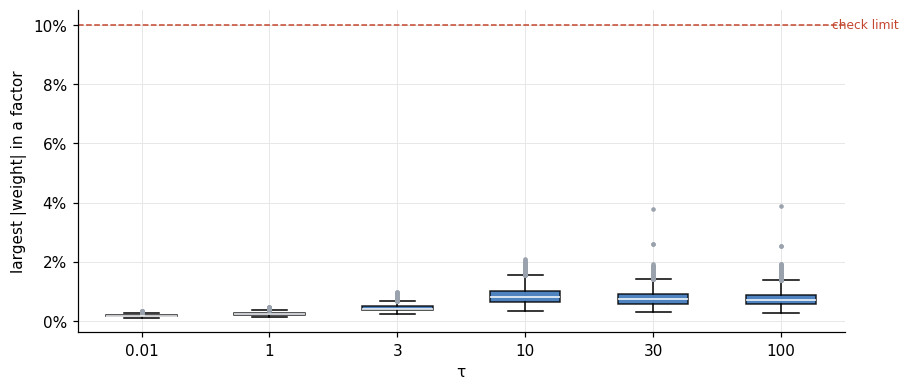

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.8))
s = stats.filter(pl.col("K") == 30)
ax.boxplot([s.filter(pl.col("tau") == t)["max_abs_w"].to_numpy() for t in TAUS], tick_labels=[str(t) for t in TAUS],
           patch_artist=True, widths=0.55, boxprops={"facecolor": BLUE, "alpha": 0.85}, medianprops={"color": "white"},
           flierprops={"markersize": 2, "markerfacecolor": GREY, "markeredgecolor": GREY})
ax.axhline(MAX_STOCK_WEIGHT, color="#c4462f", lw=1, ls="--")
ax.text(len(TAUS) + 0.4, MAX_STOCK_WEIGHT, "check limit", color="#c4462f", va="center", fontsize=8)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("τ"); ax.set_ylabel("largest |weight| in a factor"); plt.show()

## Worst case over all in-sample months, every K and τ

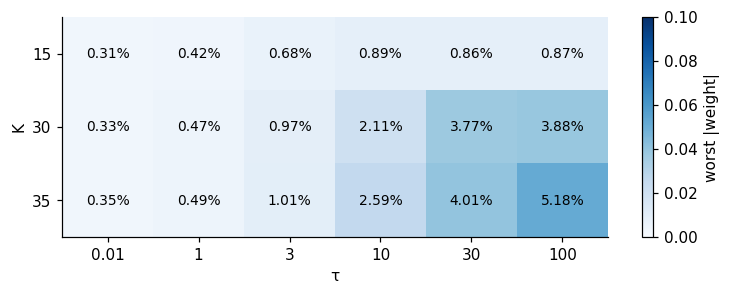

In [4]:
worst = stats.group_by("K", "tau").agg(pl.col("max_abs_w").max()).sort("K", "tau")
mat = np.array([[worst.filter((pl.col("K") == K) & (pl.col("tau") == t))["max_abs_w"].item() for t in TAUS] for K in K_VALUES])
fig, ax = plt.subplots(figsize=(8, 2.6))
im = ax.imshow(mat, cmap="Blues", vmin=0, vmax=MAX_STOCK_WEIGHT, aspect="auto")
for i in range(len(K_VALUES)):
    for j in range(len(TAUS)):
        ax.text(j, i, f"{mat[i, j]:.2%}", ha="center", va="center", fontsize=9, color="white" if mat[i, j] > 0.06 else "black")
ax.set_xticks(range(len(TAUS)), [str(t) for t in TAUS]); ax.set_yticks(range(len(K_VALUES)), K_VALUES)
ax.set_xlabel("τ"); ax.set_ylabel("K"); ax.grid(False)
fig.colorbar(im, ax=ax, label="worst |weight|"); plt.show()

## Effective number of long names per factor (1 / Σ (long weight share)²), K = 30

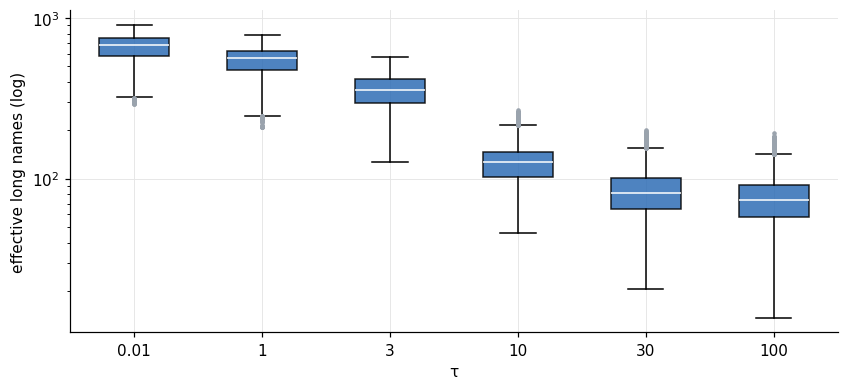

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.boxplot([s.filter(pl.col("tau") == t)["effective_long_names"].to_numpy() for t in TAUS], tick_labels=[str(t) for t in TAUS],
           patch_artist=True, widths=0.55, boxprops={"facecolor": BLUE, "alpha": 0.85}, medianprops={"color": "white"},
           flierprops={"markersize": 2, "markerfacecolor": GREY, "markeredgecolor": GREY})
ax.set_yscale("log"); ax.set_xlabel("τ"); ax.set_ylabel("effective long names (log)"); plt.show()

## All weights of one month (K = 30, τ = 10), every factor

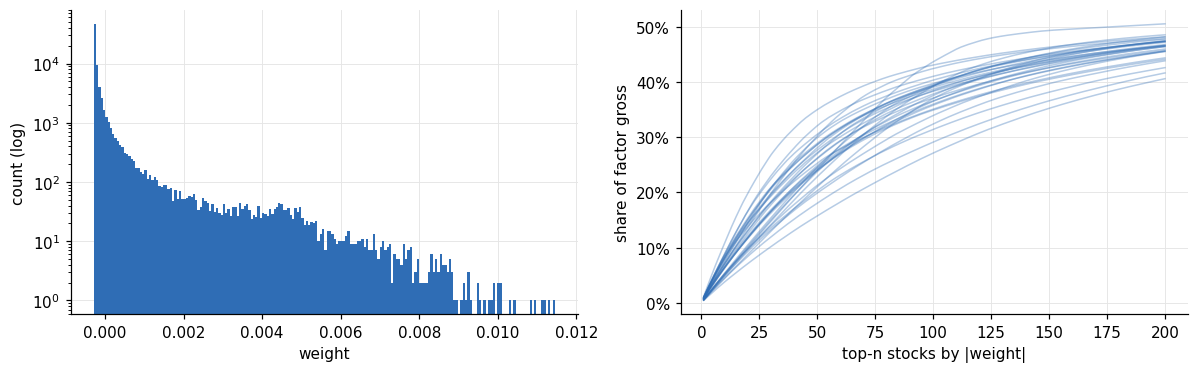

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(example.ravel(), bins=200, color=BLUE)
axes[0].set_yscale("log"); axes[0].set_xlabel("weight"); axes[0].set_ylabel("count (log)")
srt = np.sort(np.abs(example), axis=0)[::-1]
cum = np.cumsum(srt, axis=0)
for k in range(example.shape[1]):
    axes[1].plot(np.arange(1, 201), cum[:200, k], color=BLUE, alpha=0.35, lw=1)
axes[1].set_xlabel("top-n stocks by |weight|"); axes[1].set_ylabel("share of factor gross")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.show()